In [ ]:
#capstone_project_1_Numpy_matrices

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# Load Male Dataset
male_url = "https://raw.githubusercontent.com/gagolews/teaching_data/master/marek/nhanes_adult_male_bmx_2020.csv"

# Load Female Dataset
female_url = "https://raw.githubusercontent.com/gagolews/teaching_data/master/marek/nhanes_adult_female_bmx_2020.csv"

male = np.genfromtxt(male_url, delimiter=",")

female = np.genfromtxt(female_url, delimiter=",")

print("Male Dataset Shape:", male.shape)
print("Female Dataset Shape:", female.shape)

Male Dataset Shape: (4082, 7)
Female Dataset Shape: (4222, 7)


In [7]:
# Display first 5 rows of Male Dataset
print("MALE DATASET:")
print(male[:5])

# Display first 5 rows of Female Dataset
print("\nFEMALE DATASET:")
print(female[:5])

# Check missing values
print("\nMissing values in Male Dataset:", np.isnan(male).sum())
print("Missing values in Female Dataset:", np.isnan(female).sum())

MALE DATASET:
[[  nan   nan   nan   nan   nan   nan   nan]
 [ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]]

FEMALE DATASET:
[[  nan   nan   nan   nan   nan   nan   nan]
 [ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]]

Missing values in Male Dataset: 7
Missing values in Female Dataset: 7


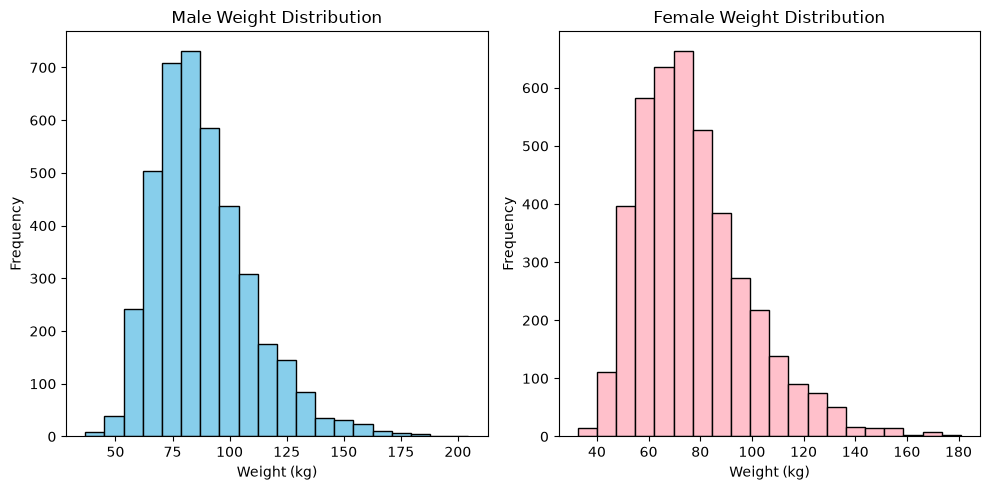

In [8]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.hist(male[:, 0], bins=20, color="skyblue", edgecolor="black")
plt.title("Male Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(female[:, 0], bins=20, color="pink", edgecolor="black")
plt.title("Female Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

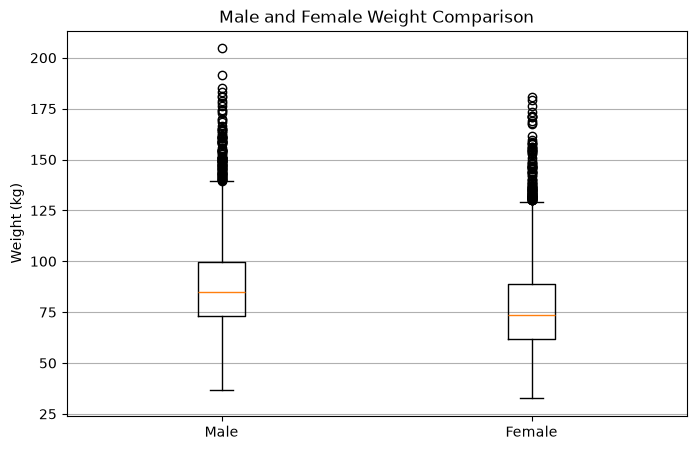

In [3]:
male_weight = male[:, 0]
female_weight = female[:, 0]

male_weight = male_weight[np.isfinite(male_weight)]
female_weight = female_weight[np.isfinite(female_weight)]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [male_weight, female_weight],
    tick_labels=["Male", "Female"]
)

plt.title("Male and Female Weight Comparison")
plt.ylabel("Weight (kg)")
plt.grid(axis="y")

plt.show()

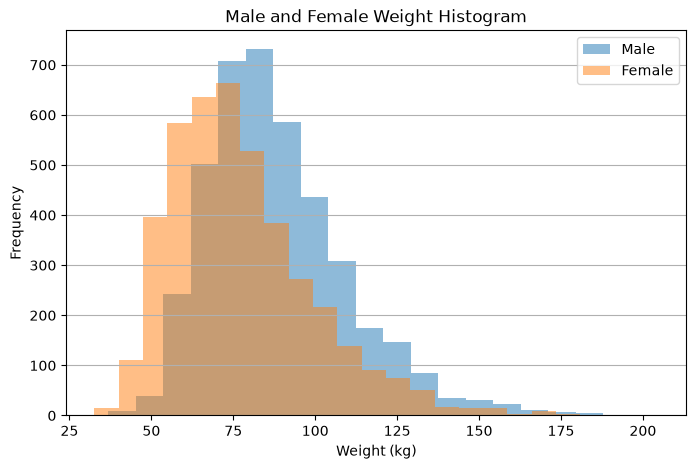

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(male[:, 0], bins=20, alpha=0.5, label="Male")
plt.hist(female[:, 0], bins=20, alpha=0.5, label="Female")

plt.title("Male and Female Weight Histogram")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y")

plt.show()

In [6]:
# Male Weight Statistics
print("MALE WEIGHT STATISTICS")

print("Mean:", np.nanmean(male[:, 0]))
print("Median:", np.nanmedian(male[:, 0]))
print("Standard Deviation:", np.nanstd(male[:, 0]))
print("Minimum:", np.nanmin(male[:, 0]))
print("Maximum:", np.nanmax(male[:, 0]))

# Female Weight Statistics
print("\nFEMALE WEIGHT STATISTICS")

print("Mean:", np.nanmean(female[:, 0]))
print("Median:", np.nanmedian(female[:, 0]))
print("Standard Deviation:", np.nanstd(female[:, 0]))
print("Minimum:", np.nanmin(female[:, 0]))
print("Maximum:", np.nanmax(female[:, 0]))

MALE WEIGHT STATISTICS
Mean: 88.36454300416565
Median: 85.0
Standard Deviation: 21.418936717962495
Minimum: 36.8
Maximum: 204.6

FEMALE WEIGHT STATISTICS
Mean: 77.40379057095475
Median: 73.6
Standard Deviation: 21.54250829019315
Minimum: 32.6
Maximum: 180.9


In [7]:
# Calculate BMI for Female Dataset

female_bmi = female[:, 0] / (female[:, 1] / 100) ** 2

print("Female BMI Values:")
print(female_bmi[:10])

print("\nAverage Female BMI:", np.nanmean(female_bmi))
print("Minimum Female BMI:", np.nanmin(female_bmi))
print("Maximum Female BMI:", np.nanmax(female_bmi))

Female BMI Values:
[        nan 37.83504078 39.06972037 28.09265496 24.90437849 23.17879132
 29.61110588 23.87973559 31.796902   30.46008939]

Average Female BMI: 30.103378810961285
Minimum Female BMI: 14.20340053807361
Maximum Female BMI: 67.03689493237839


In [10]:
# Add BMI as a new column to Female Dataset

female = np.column_stack((female, female_bmi))

print("Updated Female Dataset Shape:")
print(female.shape)

print("\nFemale Dataset with BMI:")
print(female[:5])

Updated Female Dataset Shape:
(4222, 8)

Female Dataset with BMI:
[[         nan          nan          nan          nan          nan
           nan          nan          nan]
 [ 97.1        160.2         34.7         40.8         35.8
  126.1        117.9         37.83504078]
 [ 91.1        152.7         33.5         33.          38.5
  125.5        103.1         39.06972037]
 [ 73.         161.2         37.4         38.          31.8
  106.2         92.          28.09265496]
 [ 61.7        157.4         38.          34.7         29.
  101.          90.5         24.90437849]]


In [11]:
# Standardize Female Dataset using Z-Score

female_mean = np.nanmean(female, axis=0)
female_std = np.nanstd(female, axis=0)

zfemale = (female - female_mean) / female_std

print("Standardized Female Dataset:")
print(zfemale[:5])

print("\nZ-Female Dataset Shape:")
print(zfemale.shape)

Standardized Female Dataset:
[[        nan         nan         nan         nan         nan         nan
          nan         nan]
 [ 0.91429508  0.00895038 -0.56739463  1.13298804  0.55084546  1.08316157
   1.11578462  0.9969677 ]
 [ 0.63577599 -1.05306843 -1.07893145 -1.29349161  1.03221804  1.04475528
   0.265089    1.15617483]
 [-0.2044233   0.15055289  0.5835632   0.26194406 -0.1622991  -0.19064688
  -0.37293272 -0.25927501]
 [-0.7289676  -0.38753664  0.83933161 -0.76464348 -0.66150029 -0.52350135
  -0.45915188 -0.67039085]]

Z-Female Dataset Shape:
(4222, 8)


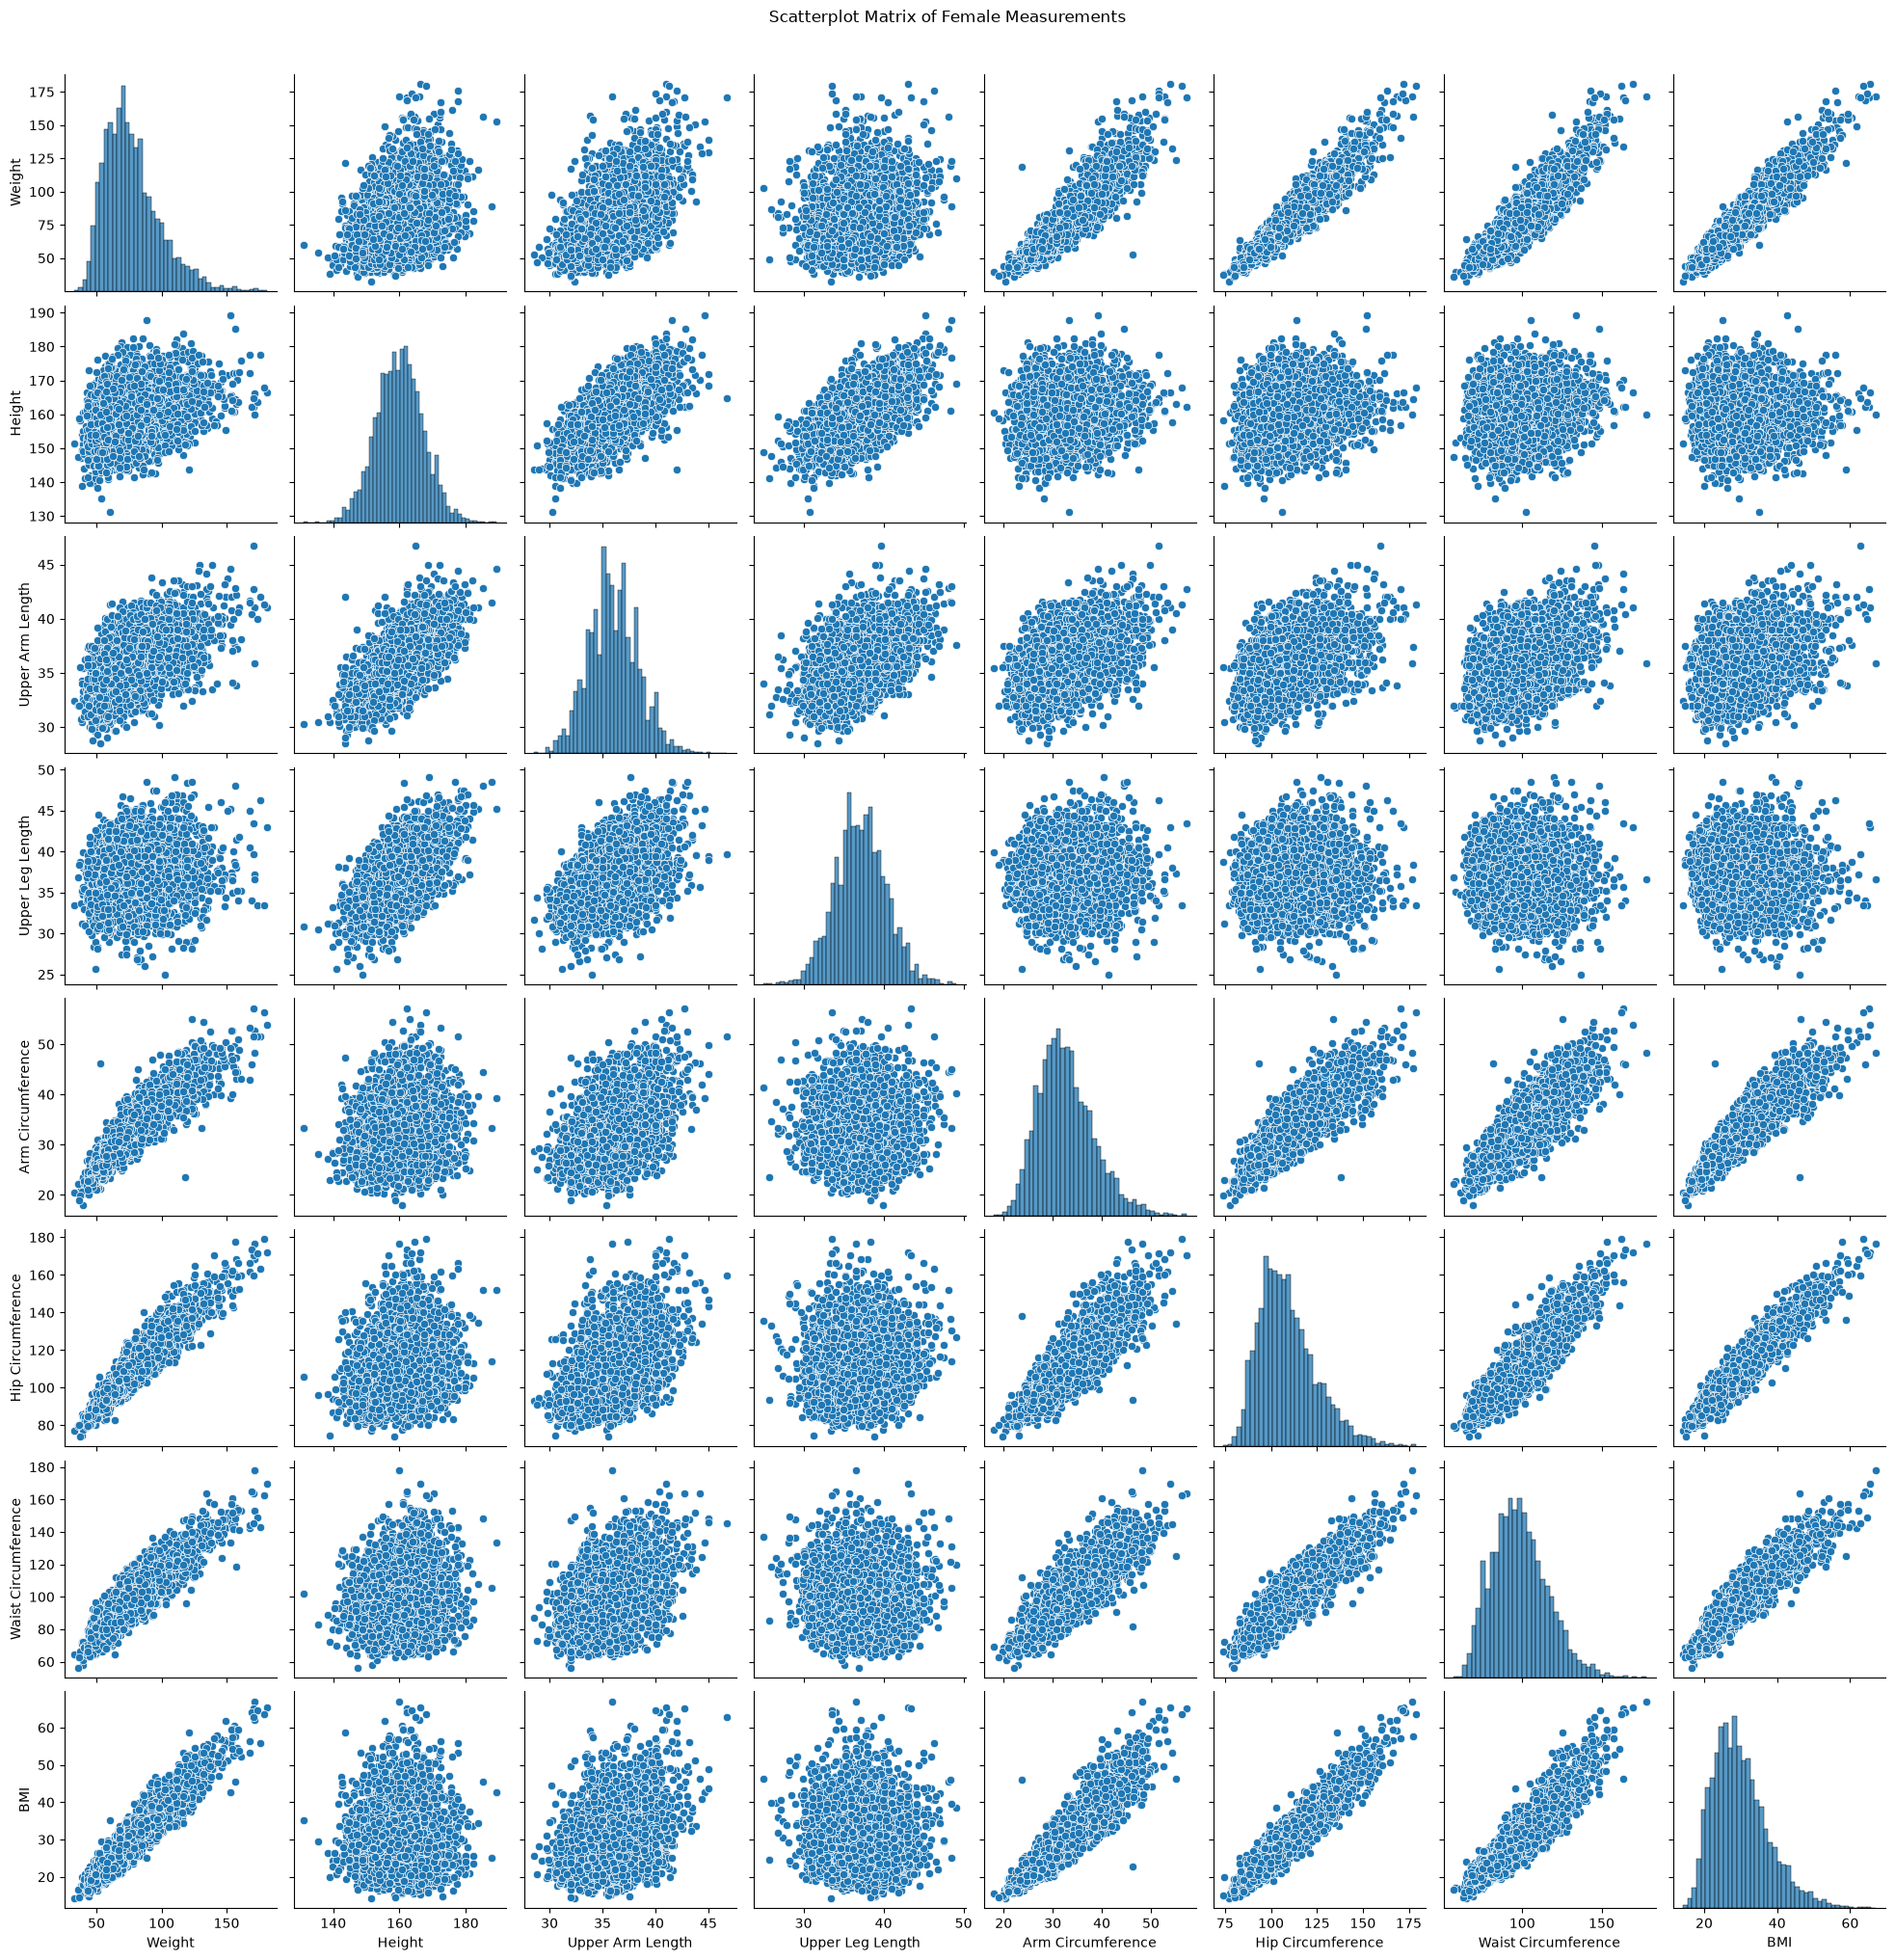

In [13]:
# Scatterplot Matrix

columns = [
    "Weight",
    "Height",
    "Upper Arm Length",
    "Upper Leg Length",
    "Arm Circumference",
    "Hip Circumference",
    "Waist Circumference",
    "BMI"
]

female_df = pd.DataFrame(female, columns=columns)

sns.pairplot(female_df, diag_kind="hist")

plt.suptitle("Scatterplot Matrix of Female Measurements", y=1.02)

plt.show()

In [14]:
# Pearson Correlation
pearson_corr = female_df.corr(method="pearson")

print("PEARSON CORRELATION:")
print(pearson_corr)

# Spearman Correlation
spearman_corr = female_df.corr(method="spearman")

print("\nSPEARMAN CORRELATION:")
print(spearman_corr)

PEARSON CORRELATION:
                       Weight    Height  Upper Arm Length  Upper Leg Length  \
Weight               1.000000  0.345496          0.551563          0.193186   
Height               0.345496  1.000000          0.667911          0.657202   
Upper Arm Length     0.551563  0.667911          1.000000          0.475645   
Upper Leg Length     0.193186  0.657202          0.475645          1.000000   
Arm Circumference    0.905385  0.151955          0.453122          0.079876   
Hip Circumference    0.946553  0.202895          0.459400          0.100268   
Waist Circumference  0.904550  0.126547          0.427893         -0.034803   
BMI                  0.945900  0.033077          0.364660         -0.014819   

                     Arm Circumference  Hip Circumference  \
Weight                        0.905385           0.946553   
Height                        0.151955           0.202895   
Upper Arm Length              0.453122           0.459400   
Upper Leg Length       

In [15]:
# Calculate Waist-to-Height Ratio (WHtR)

whtr = female[:, 6] / female[:, 1]

# Calculate Waist-to-Hip Ratio (WHR)

whr = female[:, 6] / female[:, 5]

print("First 10 Waist-to-Height Ratio values:")
print(whtr[:10])

print("\nFirst 10 Waist-to-Hip Ratio values:")
print(whr[:10])

print("\nAverage WHtR:", np.nanmean(whtr))
print("Average WHR:", np.nanmean(whr))

First 10 Waist-to-Height Ratio values:
[       nan 0.73595506 0.67518009 0.5707196  0.57496823 0.47347995
 0.58604008 0.57477477 0.63883495 0.61243719]

First 10 Waist-to-Hip Ratio values:
[       nan 0.93497224 0.82151394 0.86629002 0.8960396  0.79135135
 0.79475164 0.99376947 0.91643454 0.95588235]

Average WHtR: 0.6156169264982299
Average WHR: 0.8999790698583346


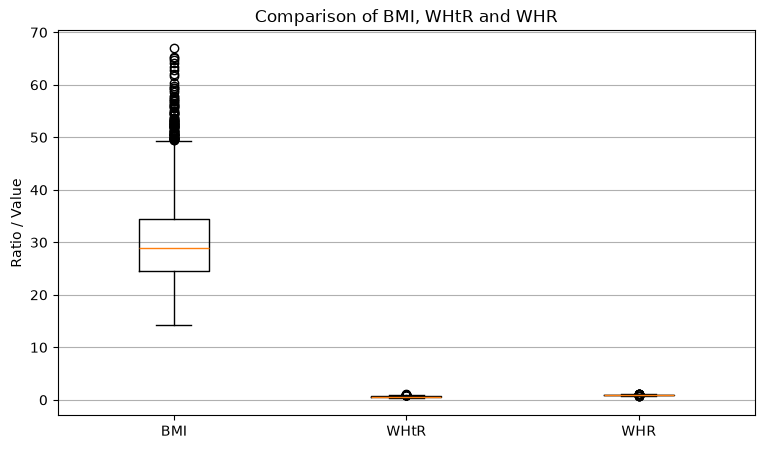

In [16]:
# Compare BMI, WHtR and WHR

bmi_values = female[:, 7]

bmi_values = bmi_values[np.isfinite(bmi_values)]
whtr_values = whtr[np.isfinite(whtr)]
whr_values = whr[np.isfinite(whr)]

plt.figure(figsize=(9, 5))

plt.boxplot(
    [bmi_values, whtr_values, whr_values],
    tick_labels=["BMI", "WHtR", "WHR"]
)

plt.title("Comparison of BMI, WHtR and WHR")
plt.ylabel("Ratio / Value")
plt.grid(axis="y")

plt.show()

In [17]:
print("STRENGTHS AND LIMITATIONS")

print("\n1. BMI")
print("Strength: Easy to calculate using weight and height.")
print("Limitation: Does not directly measure body fat.")

print("\n2. WHtR")
print("Strength: Compares waist size with height.")
print("Limitation: Does not directly measure body fat.")

print("\n3. WHR")
print("Strength: Compares waist circumference with hip circumference.")
print("Limitation: Does not directly measure total body fat.")

STRENGTHS AND LIMITATIONS

1. BMI
Strength: Easy to calculate using weight and height.
Limitation: Does not directly measure body fat.

2. WHtR
Strength: Compares waist size with height.
Limitation: Does not directly measure body fat.

3. WHR
Strength: Compares waist circumference with hip circumference.
Limitation: Does not directly measure total body fat.


In [19]:
# Find 5 Lowest and 5 Highest BMI Participants

valid_indices = np.where(np.isfinite(female[:, 7]))[0]

sorted_indices = valid_indices[
    np.argsort(female[valid_indices, 7])
]

# 5 Lowest BMI
lowest_bmi = sorted_indices[:5]

print("5 LOWEST BMI PARTICIPANTS")
print(female[lowest_bmi, 7])

# 5 Highest BMI
highest_bmi = sorted_indices[-5:][::-1]

print("\n5 HIGHEST BMI PARTICIPANTS")
print(female[highest_bmi, 7])

# Compare Standardized Measurements
print("\nLOWEST BMI STANDARDIZED MEASUREMENTS")
print(zfemale[lowest_bmi, :])

print("\nHIGHEST BMI STANDARDIZED MEASUREMENTS")
print(zfemale[highest_bmi, :])

5 LOWEST BMI PARTICIPANTS
[14.20340054 14.63273036 14.81882399 15.04456103 15.42130871]

5 HIGHEST BMI PARTICIPANTS
[67.03689493 65.33289802 65.11544005 64.7070699  64.19895366]

LOWEST BMI STANDARDIZED MEASUREMENTS
[[-2.07978523 -1.22299143 -1.5478402  -1.16905675 -2.1947611  -2.0405496
  -1.94212128 -2.05024028]
 [-1.88017988 -0.18929313 -1.71835247  0.38637892 -2.4443617  -1.85491922
  -2.05708015 -1.99487987]
 [-1.53667299  1.80730222  0.62619127  0.5730312  -2.26607556 -1.6756899
  -1.7064556  -1.97088383]
 [-1.843044   -0.26009438 -0.22637009  0.51081377 -2.30173278 -2.25178417
  -1.85590213 -1.94177591]
 [-1.61094475  0.88688592 -0.09848588  0.47970506 -2.21258971 -1.82931504
  -1.71220354 -1.89319577]]

HIGHEST BMI STANDARDIZED MEASUREMENTS
[[ 4.36328993 -0.03353037 -0.05585782 -0.17357792  2.77942222  4.31569054
   4.57029862  4.76243308]
 [ 4.8042785   0.88688592  2.11817365  1.81737973  3.77782461  4.02124236
   4.08172343  4.54270932]
 [ 4.34936397  0.27799514  2.84285081  